In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)

In [29]:
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


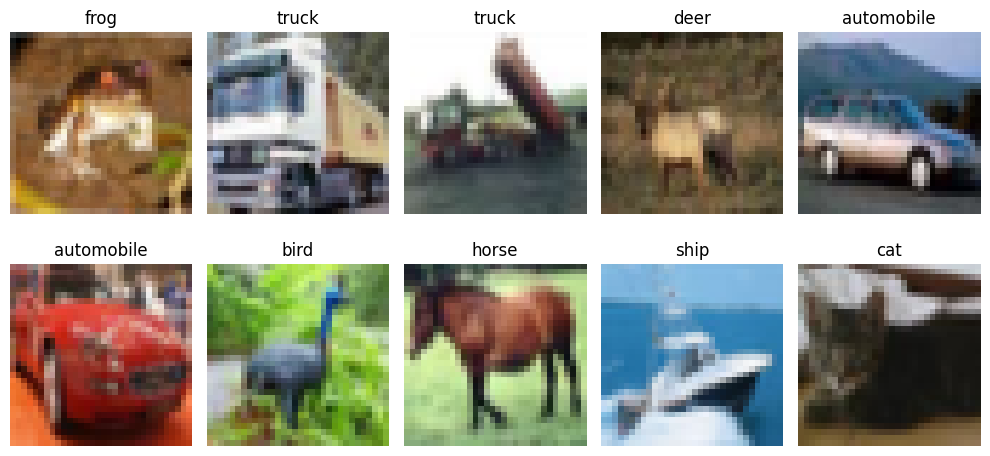

In [30]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [31]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [32]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [33]:
model = models.Sequential([

    layers.Input(shape=(32, 32, 3)),

    data_augmentation,

    # Block 1
    layers.Conv2D(32, (3, 3), padding='same',
                  use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Conv2D(32, (3, 3), padding='same',
                  use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Block 2
    layers.Conv2D(64, (3, 3), padding='same',
                  use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Conv2D(64, (3, 3), padding='same',
                  use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Block 3
    layers.Conv2D(128, (3, 3), padding='same',
                  use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Conv2D(128, (3, 3), padding='same',
                  use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Classification
    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 552,426 (2.11 MB)

 Trainable params: 551,274 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [34]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [47]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

history = model.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping, lr_scheduler]
)

Epoch 1/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.7579 - loss: 0.7105 - val_accuracy: 0.7348 - val_loss: 0.7840 - learning_rate: 0.0010
Epoch 2/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.7656 - loss: 0.6988 - val_accuracy: 0.7645 - val_loss: 0.7208 - learning_rate: 0.0010
Epoch 3/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.7705 - loss: 0.6805 - val_accuracy: 0.7981 - val_loss: 0.5920 - learning_rate: 0.0010
Epoch 4/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.7691 - loss: 0.6758 - val_accuracy: 0.7931 - val_loss: 0.6161 - learning_rate: 0.0010
Epoch 5/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.7703 - loss: 0.6735 - val_accuracy: 0.7461 - val_loss: 0.7854 - learning_rate: 0.0010
Epoch 6/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.7766 - loss: 0.6546 - val_accuracy: 0.7904 - val_loss: 0.6380 - learning_rate: 0.0010
Epoch 7/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.7914 - l

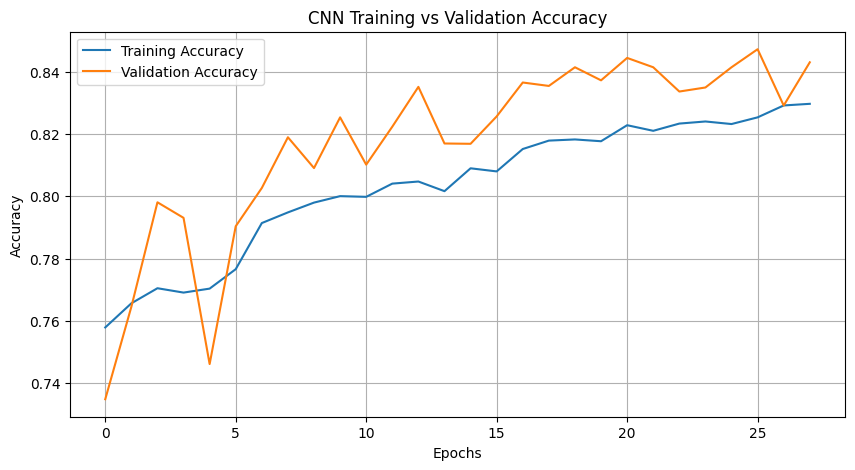

In [48]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('CNN Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)

plt.show()

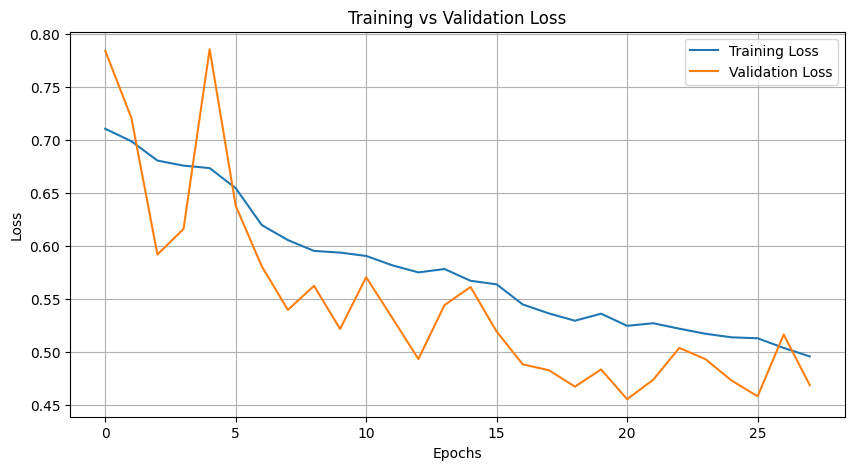

In [49]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)

plt.show()

In [50]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8387 - loss: 0.4771
Test Loss: 0.4770689904689789
Test Accuracy: 0.838699996471405


In [51]:
predictions = model.predict(x_test)

y_pred = np.argmax(predictions, axis=1)

y_true = y_test.flatten()

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

    airplane       0.88      0.84      0.86      1000
  automobile       0.91      0.94      0.93      1000
        bird       0.85      0.73      0.78      1000
         cat       0.79      0.67      0.72      1000
        deer       0.79      0.82      0.80      1000
         dog       0.81      0.74      0.77      1000
        frog       0.75      0.94      0.83      1000
       horse       0.86      0.88      0.87      1000
        ship       0.93      0.91      0.92      1000
       truck       0.84      0.92      0.88      1000

    accuracy                           0.84     10000
   macro avg       0.84      0.84      0.84     10000
weighted avg       0.84      0.84      0.84     10000



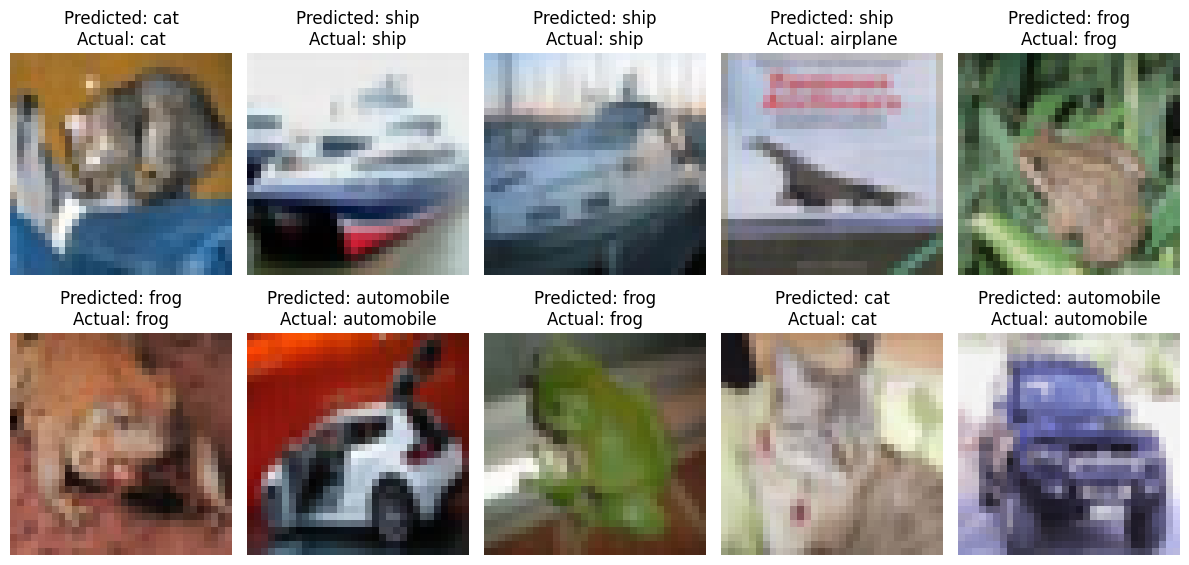

In [40]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i])

    predicted = class_names[y_pred[i]]
    actual = class_names[y_true[i]]

    plt.title(
        f"Predicted: {predicted}\nActual: {actual}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [41]:
correct = np.sum(y_pred == y_true)
incorrect = np.sum(y_pred != y_true)

print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)

print("Accuracy:", correct / len(y_true) * 100)

Correct predictions: 8031
Incorrect predictions: 1969
Accuracy: 80.31


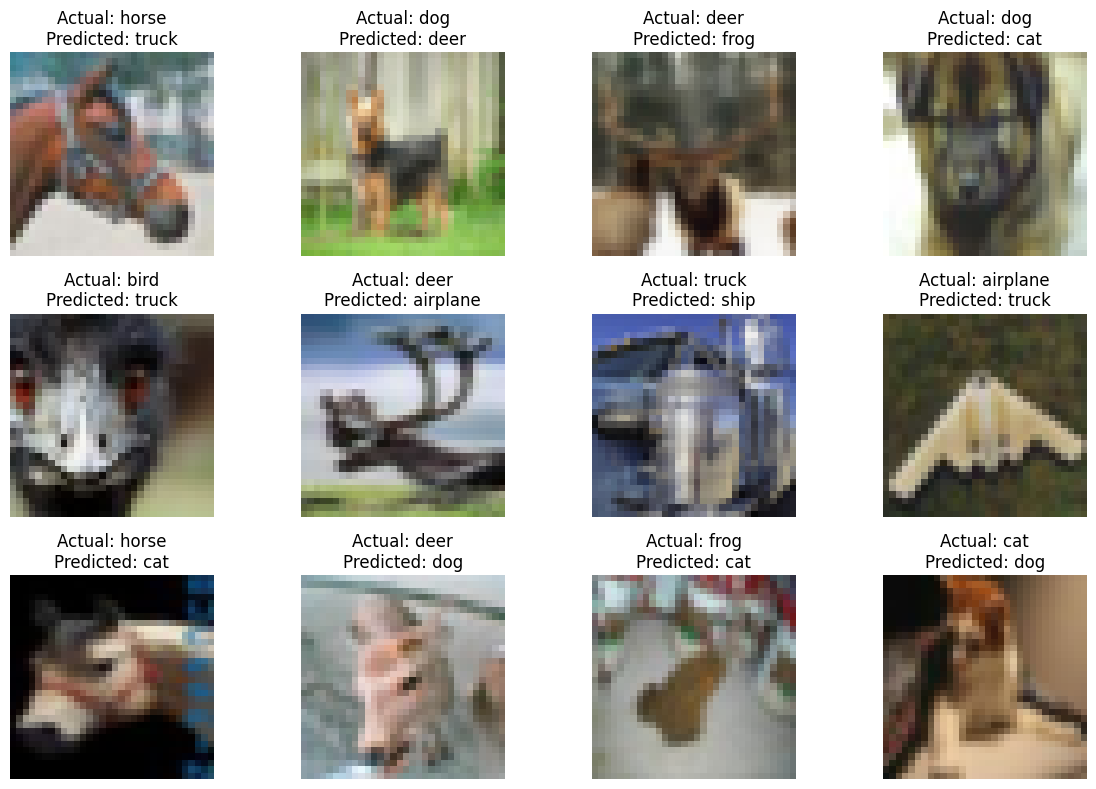

In [52]:
wrong_indices = np.where(y_pred != y_true)[0]

plt.figure(figsize=(12, 8))

for i, idx in enumerate(wrong_indices[:12]):
    plt.subplot(3, 4, i + 1)

    plt.imshow(x_test[idx])

    plt.title(
        f"Actual: {class_names[y_true[idx]]}\n"
        f"Predicted: {class_names[y_pred[idx]]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

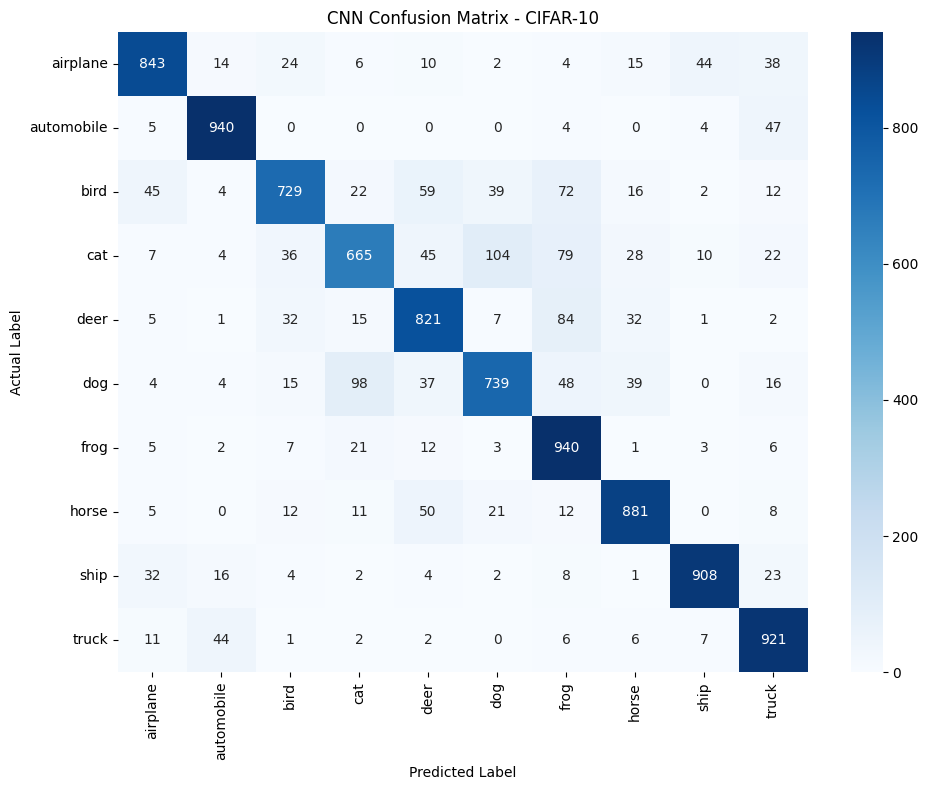

In [53]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('CNN Confusion Matrix - CIFAR-10')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


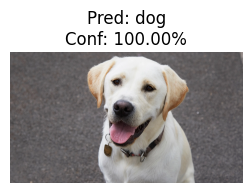

In [54]:
import requests
from io import BytesIO
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Replace with a DIRECT image URL (e.g., from Wikimedia Commons or "Copy image address")
img_url = 'https://www.guidedogs.org.uk/api/media/v3/assets/blt437ba089a41efe14/bltebdb7658d31cf031/68f77e00d1d5e9187e9b81d1/Golden_puppy_sitting.jpg?format=webp&width=3840&quality=75'

# Add a User-Agent header so websites don't block the download
headers = {'User-Agent': 'Mozilla/5.0'}
response = requests.get(img_url, headers=headers)

# .convert('RGB') ensures it always has 3 color channels
img = Image.open(BytesIO(response.content)).convert('RGB')

# Resize to 32x32 pixels to match CIFAR-10
img_resized = img.resize((32, 32))

# Normalize and add batch dimension -> (1, 32, 32, 3)
img_array = np.array(img_resized) / 255.0
img_batch = np.expand_dims(img_array, axis=0)

# Predict
predictions = model.predict(img_batch)
predicted_class_idx = np.argmax(predictions[0])
predicted_class_name = class_names[predicted_class_idx]
confidence = np.max(predictions[0]) * 100

# Display
plt.figure(figsize=(3, 3))
plt.imshow(img)
plt.title(f"Pred: {predicted_class_name}\nConf: {confidence:.2f}%")
plt.axis('off')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


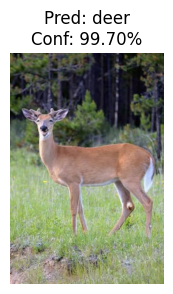

In [55]:
import requests
from io import BytesIO
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Replace with a DIRECT image URL (e.g., from Wikimedia Commons or "Copy image address")
img_url = 'https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSz4MFgrMCtQhvVMiefSVVFd79jf8Edt_BJ5q_n_K1O4g&s=10'

# Add a User-Agent header so websites don't block the download
headers = {'User-Agent': 'Mozilla/5.0'}
response = requests.get(img_url, headers=headers)

# .convert('RGB') ensures it always has 3 color channels
img = Image.open(BytesIO(response.content)).convert('RGB')

# Resize to 32x32 pixels to match CIFAR-10
img_resized = img.resize((32, 32))

# Normalize and add batch dimension -> (1, 32, 32, 3)
img_array = np.array(img_resized) / 255.0
img_batch = np.expand_dims(img_array, axis=0)

# Predict
predictions = model.predict(img_batch)
predicted_class_idx = np.argmax(predictions[0])
predicted_class_name = class_names[predicted_class_idx]
confidence = np.max(predictions[0]) * 100

# Display
plt.figure(figsize=(3, 3))
plt.imshow(img)
plt.title(f"Pred: {predicted_class_name}\nConf: {confidence:.2f}%")
plt.axis('off')
plt.show()

In [56]:
model.save("cifar10_cnn_model.keras")

print("Model saved successfully!")

Model saved successfully!
